# CS 363M Final Project
Luke Henderson (ldh2674)  
add names

## Introduction

Parkinson's disease is a progressive neurodegenerative disorder of the central nervous system that primarily affects movement. It affects approximately 1 million Americans, with common symptoms including tremors, stiffness, and slowed movement. Although there is no cure, medications and deep brain stimulation can manage symptoms. The disease is not typically directly fatal, but complications can be life-threatening. Early diagnosis allows for earlier treatment and improved quality of life.

Clinicians assess disease severity with the Unified Parkinson's Disease Rating Scale. Motor UPDRS measures motor symptoms, and total UPDRS measures overall severity, including motor and non-motor symptoms. Higher scores indicate more severe symptoms. This project predicts total UPDRS from voice measurements so that changes in disease severity can be monitored remotely.

Keep `modeling_workflow.py` alongside this notebook when running or sharing it. Run all cells from the project root; CSV result files are regenerated by the notebook.


## Dataset Description

The Parkinson's Telemonitoring Dataset contains 5,875 voice recordings from 42 patients with early-stage Parkinson's disease, collected over a six-month period. Developed by researchers at the University of Oxford in collaboration with 10 U.S. medical centers and Intel, the dataset explores how changes in speech can be used to monitor Parkinson's disease progression remotely.

Each recording contains 16 biomedical voice measurements, along with patient demographics, time since enrollment, Motor_UPDRS, and Total_UPDRS. The prediction target is total UPDRS. It is the broader severity score because it includes motor and non-motor symptoms. Motor UPDRS remains in the dataset for validity checks and is excluded from the predictors.

The features of the dataset are as follows: 
- Subject: Integer that uniquely identifies each subject  
- Age: Subject age  
- Sex: Subject gender ‘0’ - male, ‘1’ - female  
- Test_time: Time since recruitment into the trial. The integer part is the number of days since recruitment  
- Motor_UPDRS: Clinician’s motor UPDRS score, linearly interpolated  
- Total_UPDRS: Clinician’s total UPDRS score, linearly interpolated  
- Jitter (%), Jitter(Abs), Jitter. RAP, Jitter. PPQ5, Jitter. DDP: Several measures of variation in fundamental frequency (Frequency parameters)  
- Shimmer, Shimmer (dB), Shimmer. APQ3, Shimmer. APQ5, Shimmer. APQ11, Shimmer. DDA: Several measures of variation in amplitude (Amplitude parameters)  
- NHR, HNR: Two measures of ratio of noise to tonal components in the voice  
- RPDE: A nonlinear dynamical complexity measure  
- DFA: Signal fractal scaling exponent  
- PPE: A nonlinear measure of fundamental frequency variation  
  
These voice measurements capture variations in pitch, loudness, noise, and vocal stability, which can be affected by Parkinson's disease. By analyzing patterns in these features, we aim to develop models that accurately predict total UPDRS and support noninvasive, remote monitoring of disease severity and progression.

## Data Prep

### Check for missing, infinite, duplicate, and repeated values

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("data/parkinsons_updrs.csv")
repeated_patient_times = df.duplicated(subset=["subject#", "test_time"])

# Check for missing values, infinities, and duplicate rows
print("Missing values:", df.isna().sum().sum())
print("Infinite values:", np.isinf(df).sum().sum())
print(f"Repeated patient/time pairs: {repeated_patient_times.sum():,}")     # multiple recordings that have the same patient and record time as another row (expected, not a problem)
print("Duplicate rows:", df.duplicated().sum())

df.head()

Missing values: 0
Infinite values: 0
Repeated patient/time pairs: 3,374
Duplicate rows: 0
Out[1]: 
   subject#  age  sex  test_time  ...     HNR     RPDE      DFA      PPE
0         1   72    0     5.6431  ...  21.640  0.41888  0.54842  0.16006
1         1   72    0    12.6660  ...  27.183  0.43493  0.56477  0.10810
2         1   72    0    19.6810  ...  23.047  0.46222  0.54405  0.21014
3         1   72    0    25.6470  ...  24.445  0.48730  0.57794  0.33277
4         1   72    0    33.6420  ...  26.126  0.47188  0.56122  0.19361

[5 rows x 22 columns]


The dataset contains no missing values, infinite values, or exact duplicate rows, so no cleaning was necessary. There are 3,374 repeated patient/time pairs, which is expected since patients can have multiple voice recordings at the same recorded time.

### Invalid values check

In [2]:
# Check for invalid or inconsistent values
print("Invalid ages:", ((df["age"] <= 0) | (df["age"] > 120)).sum())
print("Invalid sex values:", (~df["sex"].isin([0, 1])).sum())

print("Negative UPDRS scores:",
      ((df["motor_UPDRS"] < 0) | (df["total_UPDRS"] < 0)).sum())

print("Total UPDRS below motor UPDRS:",
      (df["total_UPDRS"] < df["motor_UPDRS"]).sum())

print("Negative test times:", (df["test_time"] < 0).sum())

Invalid ages: 0
Invalid sex values: 0
Negative UPDRS scores: 0
Total UPDRS below motor UPDRS: 0
Negative test times: 12



All ages, sex values, and UPDRS scores passed the validity checks. There were 12 recordings with negative test times, which may represent measurements taken before the enrollment reference date. Since these are not necessarily errors, we decided to keep them.

### Inspect outliers

In [3]:
continuous = df.drop(columns=["subject#", "sex"])

# Uses Tukeys Fences to detect outliers
q1 = continuous.quantile(0.25)
q3 = continuous.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_flags = (continuous < lower) | (continuous > upper)

outlier_counts = outlier_flags.sum()
outlier_report = pd.DataFrame({
    "lower_fence": lower,
    "upper_fence": upper,
    "outlier_count": outlier_counts,
    "outlier_percent": (outlier_flags.mean() * 100).round(2),
}).sort_values("outlier_count", ascending=False)

display(outlier_report)
print(f"Rows with at least one outlier: {outlier_flags.any(axis=1).sum():,} (all retained)")

Rows with at least one outlier: 931 (all retained)


,lower_fence,upper_fence,outlier_count,outlier_percent
NHR,-0.019807,0.062225,436,7.42
Jitter:PPQ5,-0.000640,0.005920,425,7.23
Jitter:RAP,-0.000985,0.005855,414,7.05
Jitter:DDP,-0.002980,0.017580,413,7.03
Jitter(%),-0.001250,0.011630,398,6.77
Jitter(Abs),-0.000024,0.000100,366,6.23
Shimmer,-0.011825,0.070695,333,5.67
Shimmer(dB),-0.110000,0.650000,332,5.65
Shimmer:APQ3,-0.007663,0.037518,332,5.65
Shimmer:DDA,-0.023027,0.112592,331,5.63


Using Tukey's fences (1.5 × IQR), 931 recordings were flagged as having at least one outlier. Most outliers occurred in the NHR, Jitter, and Shimmer measurements, with roughly 5–7% of values flagged for several of these features. Since extreme voice measurements could reflect genuine differences in Parkinson's symptoms, I decided not to remove any observations.

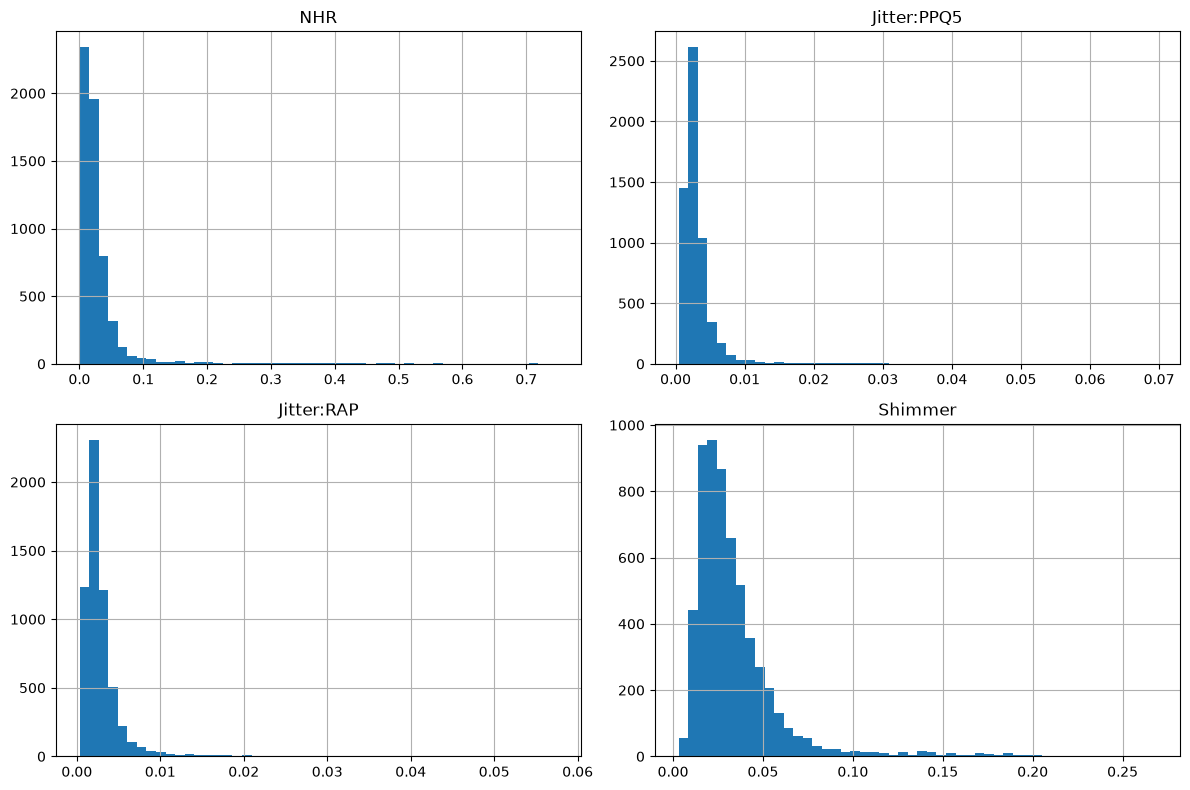

In [4]:
import matplotlib.pyplot as plt

features = ["NHR", "Jitter:PPQ5", "Jitter:RAP", "Shimmer"]

df[features].hist(bins=50, figsize=(12, 8))
plt.tight_layout()
plt.show()

The histograms show that NHR, Jitter, and Shimmer are strongly right-skewed, with most measurements concentrated at lower values and a relatively small number extending much higher. This explains why the IQR method identified so many outliers. The extreme values appear to be part of long-tailed distributions rather than obvious data errors, so I will retain them for modeling and consider transformations if needed.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_idx, test_idx = next(splitter.split(df, groups=df["subject#"]))

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

print("Training recordings:", len(train))
print("Testing recordings:", len(test))
print("Training patients:", train["subject#"].nunique())
print("Testing patients:", test["subject#"].nunique())

Training recordings: 4640
Testing recordings: 1235
Training patients: 33
Testing patients: 9


## Data Exploration

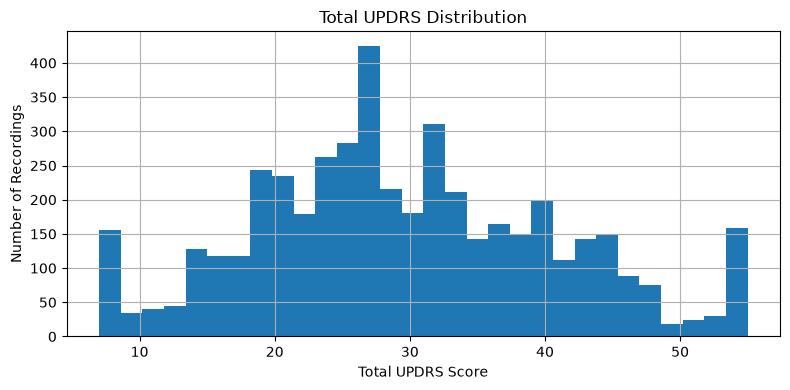

,total_UPDRS
count,4640.000000
mean,29.565597
std,11.022521
min,7.000000
25%,21.715000
50%,28.115500
75%,37.236250
max,54.992000


In [6]:
import matplotlib.pyplot as plt

target = "total_UPDRS"

ax = train[[target]].hist(bins=30, figsize=(8, 4)).flat[0]
ax.set_title("Total UPDRS Distribution")
ax.set_xlabel("Total UPDRS Score")
ax.set_ylabel("Number of Recordings")

plt.tight_layout()
plt.show()

display(train[[target]].describe())

The training set contains 4,640 recordings. Total UPDRS ranges from 7.00 to 54.99 and is concentrated around scores of 20–35. The distribution is not strongly skewed, although it has several peaks, which may reflect differences in disease severity between patients. Because the target already covers a broad range of scores, I don't see an immediate need to transform it.

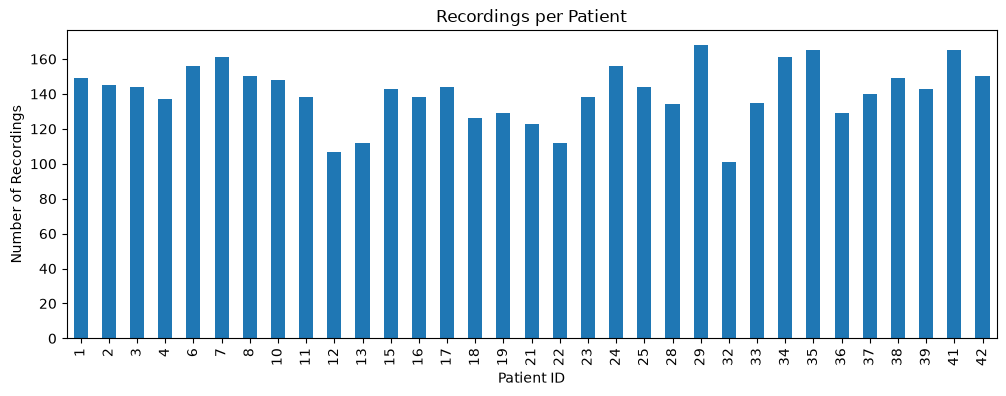

count     33.000000
mean     140.606061
std       16.695694
min      101.000000
25%      134.000000
50%      143.000000
75%      150.000000
max      168.000000
dtype: float64

In [7]:
recordings = train.groupby("subject#").size()

recordings.plot(kind="bar", figsize=(12, 4))
plt.title("Recordings per Patient")
plt.xlabel("Patient ID")
plt.ylabel("Number of Recordings")
plt.show()

display(recordings.describe())

Recording counts range from 101 to 168 and are relatively consistent across patients. Since no patient contributes substantially more recordings than the others, we do not see a need to rebalance or weight the observations by patient.

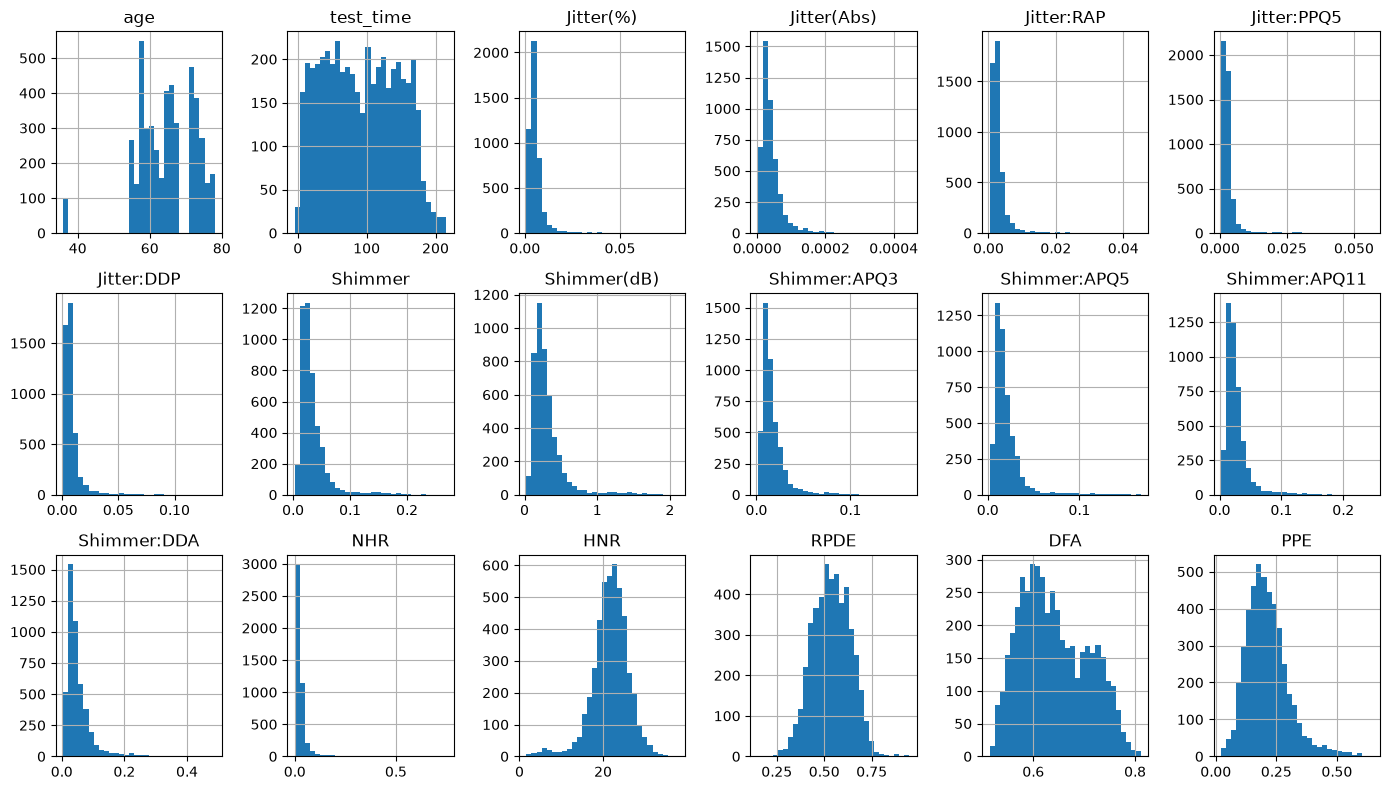

Jitter:PPQ5      6.492170
NHR              6.125149
Jitter:DDP       5.551170
Jitter:RAP       5.551042
Jitter(%)        5.264114
Shimmer:APQ5     3.822463
Jitter(Abs)      3.475975
Shimmer:APQ11    3.434173
Shimmer          3.397594
Shimmer:APQ3     3.205556
Shimmer:DDA      3.205552
Shimmer(dB)      3.181388
PPE              1.102557
DFA              0.330821
test_time        0.086193
RPDE             0.012532
age             -0.781646
HNR             -0.875499
dtype: float64

In [8]:
features = train.drop(
    columns=["subject#", "sex", "motor_UPDRS", "total_UPDRS"]
).columns

train[features].hist(bins=30, figsize=(14, 8), layout=(3, 6))
plt.tight_layout()
plt.show()

display(train[features].skew().sort_values(ascending=False))

Most of the jitter and shimmer measurements, along with NHR, are strongly right-skewed, while HNR and RPDE have more symmetric distributions. The features also vary considerably in scale so we will consider log transformations for highly skewed features and standardization for models sensitive to feature scale such as KNN.

Jitter(%) & Jitter(Abs): 0.9189
Jitter(%) & Jitter:RAP: 0.9843
Jitter(%) & Jitter:PPQ5: 0.9675
Jitter(%) & Jitter:DDP: 0.9843
Jitter(Abs) & Jitter:RAP: 0.9039
Jitter(Abs) & Jitter:DDP: 0.9039
Jitter:RAP & Jitter:PPQ5: 0.9420
Jitter:RAP & Jitter:DDP: 1.0000
Jitter:PPQ5 & Jitter:DDP: 0.9420
Jitter:PPQ5 & NHR: 0.9026
Shimmer & Shimmer(dB): 0.9934
Shimmer & Shimmer:APQ3: 0.9812
Shimmer & Shimmer:APQ5: 0.9841
Shimmer & Shimmer:APQ11: 0.9442
Shimmer & Shimmer:DDA: 0.9812
Shimmer(dB) & Shimmer:APQ3: 0.9711
Shimmer(dB) & Shimmer:APQ5: 0.9768
Shimmer(dB) & Shimmer:APQ11: 0.9450
Shimmer(dB) & Shimmer:DDA: 0.9711
Shimmer:APQ3 & Shimmer:APQ5: 0.9631
Shimmer:APQ3 & Shimmer:APQ11: 0.9024
Shimmer:APQ3 & Shimmer:DDA: 1.0000
Shimmer:APQ5 & Shimmer:APQ11: 0.9478
Shimmer:APQ5 & Shimmer:DDA: 0.9631
Shimmer:APQ11 & Shimmer:DDA: 0.9024


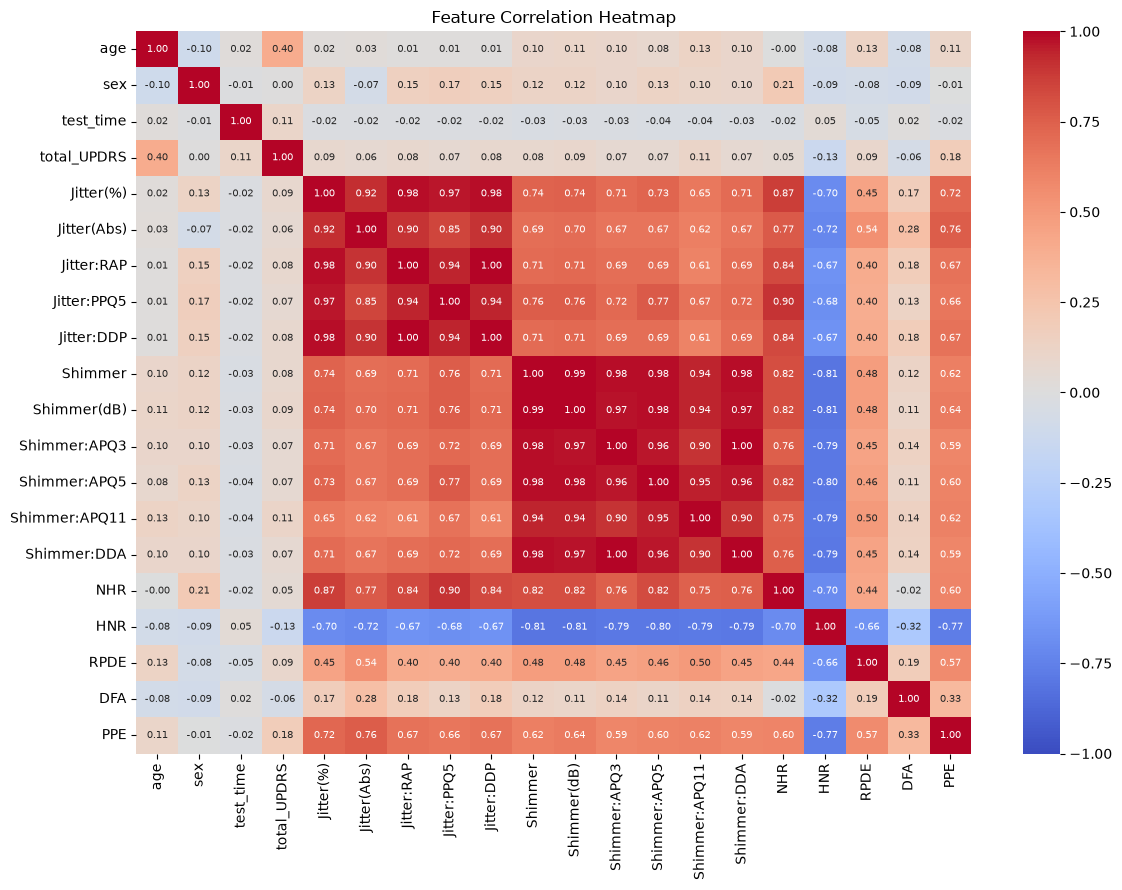

In [9]:
import seaborn as sns

correlation = train.drop(columns=["subject#", "motor_UPDRS"]).corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlation, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7})
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


feature_corr = train[features].corr()

for i in range(len(features)):
    for j in range(i + 1, len(features)):
        corr = feature_corr.iloc[i, j]

        if abs(corr) >= 0.9:
            print(f"{features[i]} & {features[j]}: {corr:.4f}")

Most of the Jitter measurements are highly correlated with each other, and the same is true for Shimmer. We could combine these measurements into one feature for Jitter and one for Shimmer instead of using each measurement individually. Age has the strongest correlation with total UPDRS. Since the voice measurements have weak linear correlations with the target, we also want to test nonlinear models such as decision trees, neural nets, and KNN.

In [10]:
target_corr = correlation.loc[features, "total_UPDRS"]

display(target_corr.sort_values(key=abs, ascending=False))

age              0.401549
PPE              0.182730
HNR             -0.128897
Shimmer:APQ11    0.110255
test_time        0.105407
RPDE             0.089096
Shimmer(dB)      0.086736
Jitter(%)        0.085094
Jitter:DDP       0.079721
Jitter:RAP       0.079706
Shimmer          0.078839
Shimmer:APQ5     0.069368
Jitter:PPQ5      0.067484
Shimmer:DDA      0.065429
Shimmer:APQ3     0.065426
Jitter(Abs)      0.064836
DFA             -0.064137
NHR              0.048002
Name: total_UPDRS, dtype: float64

Age has the strongest correlation with total UPDRS, followed by PPE. Most of the other features have correlations below 0.1 in magnitude. Since no individual feature has a strong linear relationship with the target, we are going to see how well these features work together and whether nonlinear models perform better.

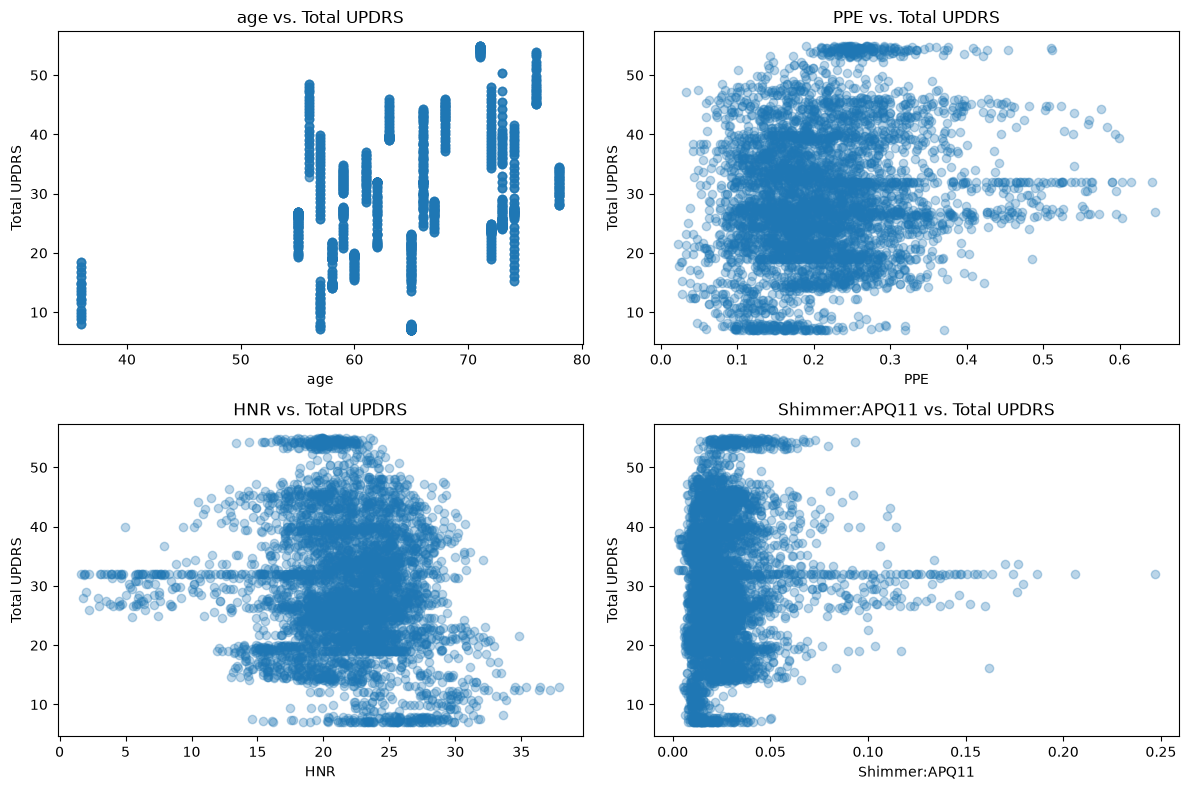

In [11]:
selected = target_corr.abs().nlargest(4).index

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(selected, axes.flat):
    ax.scatter(train[feature], train["total_UPDRS"], alpha=0.3)
    ax.set_xlabel(feature)
    ax.set_ylabel("Total UPDRS")
    ax.set_title(f"{feature} vs. Total UPDRS")

plt.tight_layout()
plt.show()

Age shows the clearest relationship with total UPDRS, with older patients generally having higher scores. The other three features are much more scattered and do not show clear linear trends. This makes it difficult to predict UPDRS from any single voice measurement, so again, this leads us to test how well the features work together in both linear and nonlinear models.

## Feature engineering

The modeling pipelines below compare original and log voice features and a regularized quadratic expansion. Scaling is fitted within each training fold; no globally scaled combined features are passed into cross-validation.

## Modeling: predicting total_UPDRS

We predict total UPDRS only. Both UPDRS columns and patient ID are excluded from predictors. The task is generalization to unseen patients, using the original 80/20 patient split (seed 42).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from modeling_workflow import load_split, compare_models, final_evaluation

X_train, X_test, y_train, y_test, groups_train, groups_test = load_split()
print(f"Training: {len(X_train)} recordings, {groups_train.nunique()} patients")
print(f"Test: {len(X_test)} recordings, {groups_test.nunique()} patients")
assert set(groups_train).isdisjoint(groups_test)
assert not {"subject#", "motor_UPDRS", "total_UPDRS"}.intersection(X_train.columns)

Training: 4640 recordings, 33 patients
Test: 1235 recordings, 9 patients


### Features and validation

Compare demographics (age, sex, recording time), voice alone, voice plus demographics, and log voice plus demographics. Log transforms use the natural logarithm of positive jitter, shimmer, and NHR values; unlike log1p, this meaningfully transforms very small values. A regularized quadratic model tests squared terms and interactions. Fixed feature sets replace supervised forward selection performed outside validation.

All scaling and transformations happen inside each pipeline. Five shared outer GroupKFold splits estimate performance; three inner patient-grouped folds select hyperparameters by MAE within each outer training subset. Untuned models use the same outer folds. This prevents both preprocessing leakage and reporting the same folds used to tune hyperparameters. Parameter grids are deliberately small for a reproducible run; they do not exhaust all possible improvements. See modeling_workflow.py for the exact candidates.

MAE is primary, with RMSE and R² as supporting metrics. Fold R² can be negative when a model is worse than that validation fold's own mean. The explicit mean baseline uses only the training fold's mean. The best result across many candidates may still be optimistic; reserve the held-out patients for one final evaluation.

In [2]:
comparison, specs = compare_models(X_train, y_train, groups_train)

Mean baseline: nested CV MAE 8.971
Linear / Demographics: nested CV MAE 8.832
Ridge / Demographics: nested CV MAE 8.712
Lasso / Demographics: nested CV MAE 8.632
KNN / Demographics: nested CV MAE 9.788
Tree / Demographics: nested CV MAE 10.561
SVR / Demographics: nested CV MAE 12.034
Forest / Demographics: nested CV MAE 11.052
Linear / Voice only: nested CV MAE 9.834
Ridge / Voice only: nested CV MAE 9.537
Lasso / Voice only: nested CV MAE 9.208
KNN / Voice only: nested CV MAE 9.467
Tree / Voice only: nested CV MAE 9.466
SVR / Voice only: nested CV MAE 10.169
Forest / Voice only: nested CV MAE 9.464
Linear / Voice + demographics: nested CV MAE 9.651
Ridge / Voice + demographics: nested CV MAE 9.099
Lasso / Voice + demographics: nested CV MAE 8.644
KNN / Voice + demographics: nested CV MAE 9.555
Tree / Voice + demographics: nested CV MAE 10.163
SVR / Voice + demographics: nested CV MAE 10.978
Forest / Voice + demographics: nested CV MAE 11.156
Linear / Log voice + demographics: nested C

/Users/evanwhite/School/CS363M/parkinsons/.venv/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py:134: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Users/evanwhite/School/CS363M/parkinsons/.venv/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "/Users/evanwhite/School/CS363M/parkinsons/.venv/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)


## Comparison

Metrics below are outer-fold means. MAE SD describes variation between folds, not a confidence interval. Positive tuning gain and MAE improvement indicate improvement over the untuned model and mean baseline, respectively.

,candidate,train MAE,untuned CV MAE,CV MAE,CV MAE SD,CV RMSE,CV R2,MAE improvement %,MAE tuning gain
0,Lasso / Demographics,8.244,8.632,8.632,1.816,10.315,-0.096,3.769,0.000
1,Lasso / Voice + demographics,8.134,8.644,8.644,1.831,10.365,-0.099,3.641,0.000
2,Lasso / Log voice + demographics,8.129,8.651,8.651,1.837,10.372,-0.100,3.561,0.000
3,Ridge / Demographics,8.272,8.832,8.712,1.733,10.382,-0.124,2.878,0.120
4,Linear / Demographics,8.303,8.832,8.832,1.723,10.448,-0.152,1.543,0.000
5,Mean baseline,8.879,8.971,8.971,2.158,10.977,-0.234,0.000,0.000
6,Ridge / Voice + demographics,8.003,9.641,9.099,1.706,10.726,-0.178,-1.430,0.542
7,Ridge / Log voice + demographics,7.946,9.869,9.159,1.713,10.849,-0.207,-2.096,0.711
8,Lasso / Voice only,8.724,9.208,9.208,2.103,11.172,-0.274,-2.650,0.000
9,KNN / Log voice + demographics,7.939,11.911,9.439,2.148,11.304,-0.297,-5.218,2.473


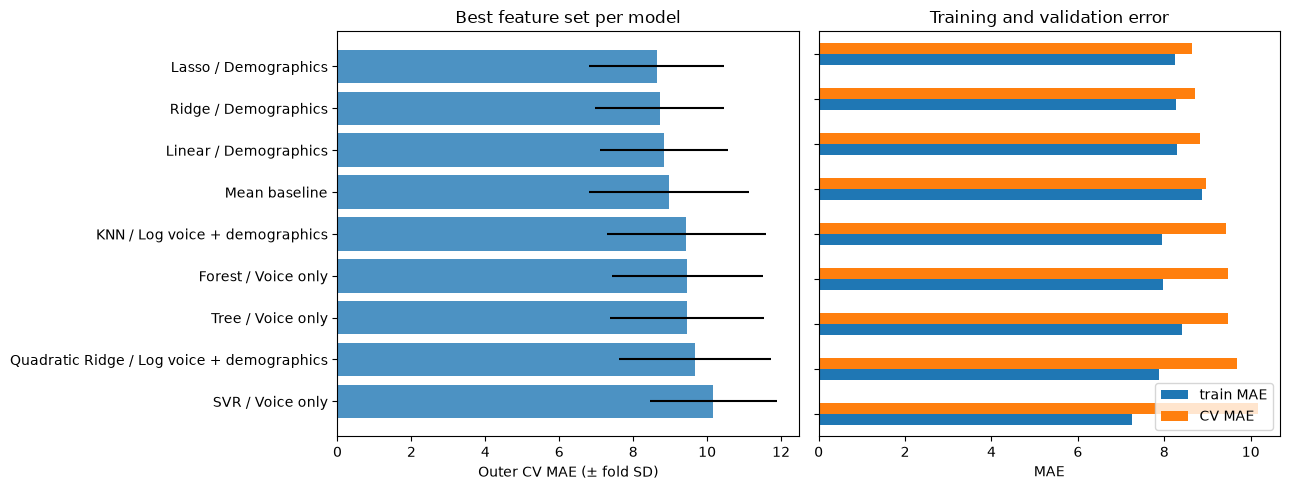

In [3]:
display(comparison.round(3))
comparison.to_csv("model_comparison.csv", index=False)

best_by_model = comparison.assign(family=comparison.candidate.str.split(" / ").str[0]).drop_duplicates("family")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot = best_by_model.sort_values("CV MAE", ascending=False)
axes[0].barh(plot.candidate, plot["CV MAE"], xerr=plot["CV MAE SD"], alpha=.8)
axes[0].set(xlabel="Outer CV MAE (± fold SD)", title="Best feature set per model")
plot.set_index("candidate")[["train MAE", "CV MAE"]].plot.barh(ax=axes[1])
axes[1].set(xlabel="MAE", ylabel="", title="Training and validation error")
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

## Final held-out evaluation

Select the smallest outer CV MAE, retune only on all training patients, and evaluate the selected model and training-mean baseline on the held-out patients. Do not use these test results to select further models. A large train/validation gap indicates possible overfitting; weak validation across models may indicate limited predictive information for new patients.

In [4]:
final_search, test_report, test_errors = final_evaluation(
    comparison, specs, X_train, X_test, y_train, y_test, groups_train, groups_test)
print("Selected by CV MAE:", comparison.iloc[0]["candidate"])
print("Final training-only tuning:", final_search.best_params_)
display(test_report.round(3))
test_report.to_csv("final_test_metrics.csv", index=False)
test_errors.to_csv("final_test_predictions.csv", index=False)

Selected by CV MAE: Lasso / Demographics
Final training-only tuning: {'model__alpha': 1}


,model,test MAE,test RMSE,test R2
0,Lasso / Demographics,9.544,10.425,-0.312
1,Mean baseline,7.991,9.467,-0.082


### Prediction and residual diagnostics

Residual = actual − predicted. Positive residuals mean underprediction. Patient MAE gives each patient a separate summary. Severity bins are descriptive only; they are not clinical categories.

Equal-patient average MAE: 9.628


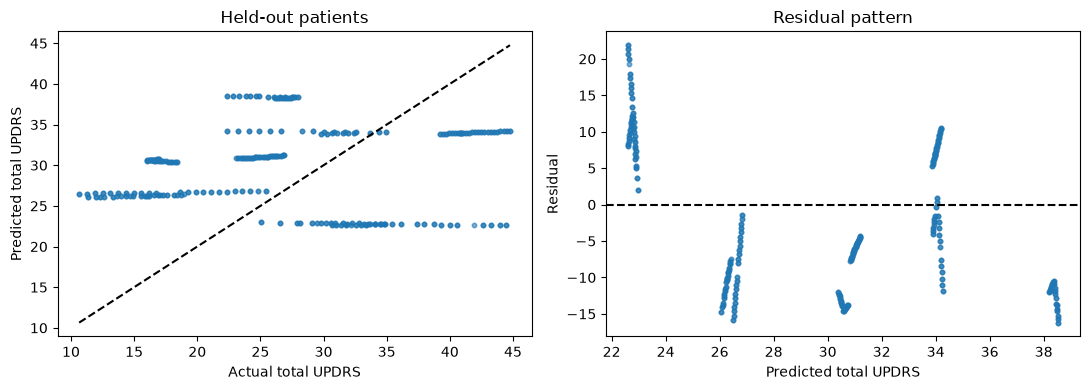

,recordings,mean_score,MAE,bias
patient,,,,
5,156,41.854,7.825,7.825
9,152,25.077,5.945,-5.945
14,136,18.017,8.650,-8.650
20,134,16.931,13.642,-13.642
26,130,31.332,8.564,8.564
27,129,15.434,10.812,-10.812
30,126,36.903,14.149,14.149
31,130,29.559,4.638,-4.519
40,142,25.954,12.429,-12.429


,recordings,patients,MAE,bias
actual score range,,,,
<20,346,3,12.124,-12.124
20–30,441,6,7.967,-7.029
30–40,277,4,8.024,6.857
>=40,171,2,10.857,10.857


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(test_errors.actual, test_errors.predicted, s=10, alpha=.25)
limits = [min(test_errors.actual.min(), test_errors.predicted.min()),
          max(test_errors.actual.max(), test_errors.predicted.max())]
axes[0].plot(limits, limits, "k--")
axes[0].set(xlabel="Actual total UPDRS", ylabel="Predicted total UPDRS", title="Held-out patients")
axes[1].scatter(test_errors.predicted, test_errors.residual, s=10, alpha=.25)
axes[1].axhline(0, color="k", linestyle="--")
axes[1].set(xlabel="Predicted total UPDRS", ylabel="Residual", title="Residual pattern")
plt.tight_layout()
plt.show()

patient_errors = test_errors.groupby("patient").agg(
    recordings=("actual", "size"), mean_score=("actual", "mean"),
    MAE=("absolute error", "mean"), bias=("residual", "mean"))
display(patient_errors.round(3))
print(f"Equal-patient average MAE: {patient_errors.MAE.mean():.3f}")
severity = pd.cut(test_errors.actual, bins=[-np.inf, 20, 30, 40, np.inf],
                  labels=["<20", "20–30", "30–40", ">=40"], right=False)
display(test_errors.groupby(severity.rename("actual score range"), observed=True).agg(
    recordings=("actual", "size"), patients=("patient", "nunique"),
    MAE=("absolute error", "mean"), bias=("residual", "mean")).round(3))

### Interpretation and limits

Use the tables to identify whether voice adds value beyond demographics and whether tuning or log transforms help. The comparison ranks by MAE; it does not optimize R² or guarantee positive R². Report an unsuccessful experiment honestly rather than weakening the patient separation.

There are only 42 patients despite thousands of recordings. Related recordings and interpolated targets limit independent information. The held-out result describes these patients and this split; it does not establish clinical utility. Fold variation and per-patient errors show sensitivity to the patients sampled. Team members must interpret the observed results and write the required process PDF themselves.

### Findings from the saved run

Demographics-only Lasso was selected by nested CV MAE (8.632 versus 8.971 for the mean baseline, a 3.77% improvement). Its mean fold R² remained negative (−0.096). Adding raw voice measurements gave MAE 8.644, log voice measurements 8.651, and the quadratic model 9.673; none improved on demographics alone. The best voice-only model had MAE 9.208, worse than the mean baseline. These experiments provide no evidence that voice features improve prediction for unseen patients under this protocol.

On the nine held-out patients, the selected model had MAE 9.544, RMSE 10.425, and R² −0.312. The mean baseline performed better (MAE 7.991, RMSE 9.467, R² −0.082). The small validation gain did not generalize to this test split. We retain the model selected by CV and report this failure; we do not use the test set to choose a replacement. Improving R² remains unresolved, and this result does not support deployment for new patients.
